In [44]:
import numpy as np, json

In [45]:
test_run = '../raw-data/half-run_20261106_094614/dataset'
z = np.load(f'{test_run}/chunk_000.npz')
d = {k:z[k] for k in z.files}
meta = json.load(open(f'{test_run}/meta.json'))

t = d['t'] - d['t'][0]
for k, v in d.items():
    print(k)
    print("=====")
    print(v)

t
=====
[1.79398358e+09 1.79398358e+09 1.79398358e+09 ... 1.79398361e+09
 1.79398361e+09 1.79398361e+09]
ranges
=====
[[0.888 0.876 0.881 ... 0.679 0.677 0.691]
 [0.865 0.872 0.879 ... 0.694 0.685 0.694]
 [0.878 0.887 0.886 ... 0.684 0.685 0.688]
 ...
 [0.978 0.985 0.983 ... 6.264 6.22  5.902]
 [0.983 0.98  1.    ... 6.193 6.244 6.193]
 [0.983 0.986 0.989 ... 6.259 6.259 5.912]]
x
=====
[         nan  -0.10962302  -0.10962302 ... -13.997823   -13.997823
 -13.997823  ]
y
=====
[       nan  0.6489184  0.6489184 ... -9.036577  -9.036577  -9.036577 ]
yaw
=====
[       nan 0.14085478 0.14085478 ... 0.70202875 0.70202875 0.70202875]
vx
=====
[nan  0.  0. ...  0.  0.  0.]
vy
=====
[nan  0.  0. ...  0.  0.  0.]
wz_odom
=====
[nan  0.  0. ... -0. -0. -0.]
wz_imu
=====
[       nan 0.12207031 0.06103516 ... 0.06103516 0.06103516 0.06103516]
ax
=====
[        nan -0.05664062 -0.05810547 ... -0.05371094 -0.05371094
 -0.05761719]
ay
=====
[       nan 0.05664062 0.05761719 ... 0.05761719 0.05566406 0

In [46]:
pairs = d.items()

In [47]:
for k, v in d.items():
    print(f'{k:14s} shape={v.shape}  first: {v[:2]}')


t              shape=(1433,)  first: [1.79398358e+09 1.79398358e+09]
ranges         shape=(1433, 1081)  first: [[0.888 0.876 0.881 ... 0.679 0.677 0.691]
 [0.865 0.872 0.879 ... 0.694 0.685 0.694]]
x              shape=(1433,)  first: [        nan -0.10962302]
y              shape=(1433,)  first: [      nan 0.6489184]
yaw            shape=(1433,)  first: [       nan 0.14085478]
vx             shape=(1433,)  first: [nan  0.]
vy             shape=(1433,)  first: [nan  0.]
wz_odom        shape=(1433,)  first: [nan  0.]
wz_imu         shape=(1433,)  first: [       nan 0.12207031]
ax             shape=(1433,)  first: [        nan -0.05664062]
ay             shape=(1433,)  first: [       nan 0.05664062]
expert_steer   shape=(1433,)  first: [nan nan]
expert_speed   shape=(1433,)  first: [nan nan]
applied_steer  shape=(1433,)  first: [nan nan]
applied_speed  shape=(1433,)  first: [nan nan]
drive_steer    shape=(1433,)  first: [nan nan]
drive_speed    shape=(1433,)  first: [nan nan]
drift_offse

In [48]:
d['ranges'][0] #ok this is all the lidar readings we havek

array([0.888, 0.876, 0.881, ..., 0.679, 0.677, 0.691],
      shape=(1081,), dtype=float32)

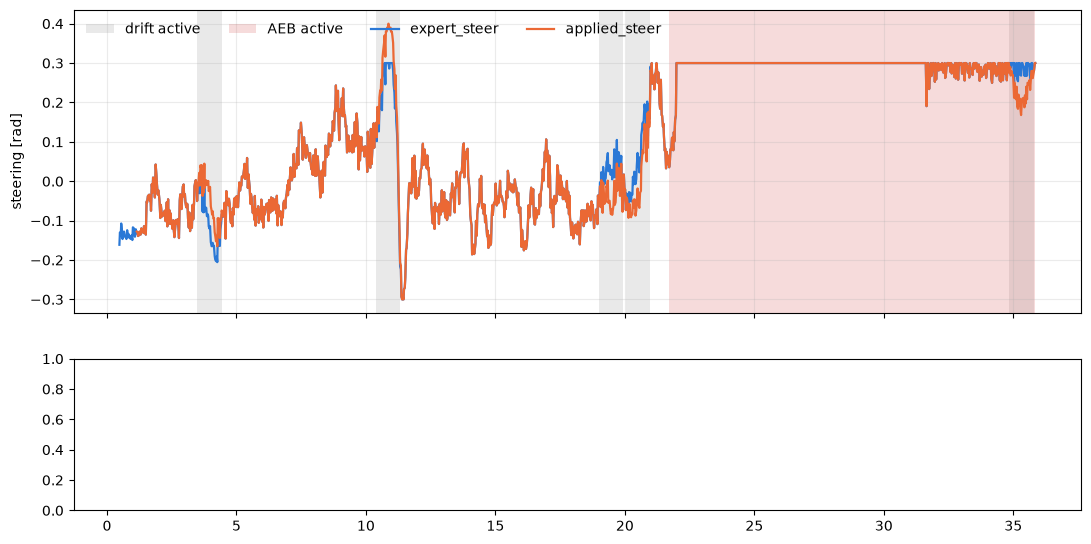

In [49]:
import numpy as np
import matplotlib.pyplot as plt

t = d['t'] - d['t'][0]
expert  = d['expert_steer']
applied = d['applied_steer']
diff    = applied - expert
drift   = d['drift_active'] == 1
aeb     = d['aeb_active'] == 1

def shade(ax, mask, color, label):
    edges = np.diff(np.concatenate([[0], mask.astype(int), [0]]))
    starts = np.where(edges == 1)[0]
    ends   = np.where(edges == -1)[0] - 1
    for i, (s, e) in enumerate(zip(starts, ends)):
        ax.axvspan(t[s], t[e], color=color, alpha=0.18, lw=0, label=label if i == 0 else None)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1]})

shade(ax1, drift, '#888888', 'drift active')
shade(ax1, aeb, '#d03b3b', 'AEB active')
ax1.plot(t, expert,  color='#2a78d6', lw=1.6, label='expert_steer')
ax1.plot(t, applied, color='#eb6834', lw=1.6, label='applied_steer')
ax1.set_ylabel('steering [rad]')
ax1.legend(loc='upper left', ncol=4, frameon=False)
ax1.grid(alpha=0.25)


#### Clean up:
clean up the data a bit.
The columns we will need as input will be ranges, and maybe -vx and wz_imu (change in yaw). expert_steer will be what the mlp will be trained on outputting (no need for speed because it is constant for now)

In [50]:
t = d['t'] - d['t'][0]                  # seconds since start
speed    = -d['vx']                     # odom speed is sign-flipped
yaw_rate = d['wz_imu'] * np.pi / 180    # IMU gives deg/s → rad/s
label    = d['expert_steer']            # what the network learns to output
n = len(t)
print('rows:', n)


rows: 1433


we will make these masks where if any of these columns are true the entire row gets dropped (that data is invalid)

In [51]:
# 1. Missing data: any input or the label is NaN (start of run, topics not ready)
nan_rows = (np.isnan(label) | np.isnan(speed) | np.isnan(yaw_rate)
            | np.isnan(d['ranges']).any(axis=1))

# 2. Safety stop: aeb_active latches, so this also cuts the tail of the run
aeb = d['aeb_active'] == 1

# 3. Car not moving: near-duplicate scans, and the expert isn't really driving
STOP_SPEED = 0.1    # m/s
stopped = speed < STOP_SPEED

#apply these masks
keep = ~(nan_rows | aeb | stopped)
print('kept so far:', keep.sum())


kept so far: 818


im worried sensors might drop data in the middle of their runs, so we will want to check if there are consecutive columns with missing data and that should be a red track if that exists

`dropped = ~keep` is True for every row we drop. To check whether missing data is spread out or comes in a few chunks, we count **blocks** (runs of consecutive dropped rows).

To compare each row with the one before it, we shift the array by one:
- `dropped[1:]`: rows 1..n (row i, "current"), first element cut
- `dropped[:-1]`: rows 0..n-1 (row i-1, "previous"), last element cut

Cutting one end from each lines up every row with its previous row and keeps the lengths equal.

`dropped[1:] & ~dropped[:-1]` is True only when **the current row is dropped AND the previous row was not**, i.e. where a block **starts** (kept → dropped):

| current | previous | `~previous` | `current & ~previous` |
|---|---|---|---|
| T | F | T | **T** (block starts) |
| F | T | F | F (block ends, not counted) |
| T | T | F | F (inside a block) |
| F | F | T | F (inside kept data) |

Summing gives the number of block starts. `+ dropped[0]` adds the case where row 0 itself is dropped, since a block can start there and has no previous row to compare with.

Note: `dropped[1:] != dropped[:-1]` (XOR) would be True at **every** cha

In [52]:
dropped = ~keep #things to drop
blocks = np.sum(dropped[1:] & ~dropped[:-1]) + dropped[0] 
print('dropped rows:  ', dropped.sum())
print('dropped blocks:', blocks)

dropped rows:   615
dropped blocks: 2


In [53]:
starts = np.where(dropped[1:] & ~dropped[:-1])[0] + 1   # kept → dropped
ends   = np.where(~dropped[1:] & dropped[:-1])[0] + 1   # dropped → kept
if dropped[0]:  starts = np.r_[0, starts]               # block starts at row 0
if dropped[-1]: ends   = np.r_[ends, len(dropped)]      # block runs to the last row

for s, e in zip(starts, ends):
    print(f'rows {s}–{e-1}: {e - s} rows  ({t[s]:.2f}–{t[e-1]:.2f} s)')


rows 0–48: 49 rows  (0.00–1.20 s)
rows 867–1432: 566 rows  (21.71–35.85 s)


## Cleaning as reusable functions

The cells above did the cleaning step by step on the half-run. Below, the same steps are wrapped in
functions so every run is cleaned **the same way**, with only its settings (e.g. the cut time) changing.

Pipeline for one run:
1. `load_run`: load all `chunk_*.npz` files of a run into one dict `d` (same as `d` above)
2. `calibrate`: apply the sensor fixes (`-vx`, `wz_imu` deg/s → rad/s) and pick the label
3. `make_masks`: one True/False mask per drop reason, then `keep` and `final`
4. `drop_report`: print how many rows each reason drops, and the blocks of dropped rows
5. `select_clean`: keep only the rows in `final` and only the columns we need

`clean_run` calls all of them in order.

**Clean each run separately and combine afterwards.** If runs were concatenated first, the
previous-scan rule could pair the last scan of one run with the first scan of the next.

### Settings
- `STOP_SPEED`: below this speed (m/s) the car counts as stopped.
- `MAX_GAP`: the longest allowed time between a scan and its previous scan. A normal scan period is ~0.027 s.
  0.04 s (~1.5 periods) allows normal jitter but rejects a missed scan (~0.05 s) or a bigger gap.
  The 1-run has a 0.62 s gap at ~50 s, and all runs have a few 0.05 s gaps.
- `RUNS`: one entry per run we want to use, keyed by the run id (the folder prefix can change).
  `cut` is the time (s since start) after which we drop everything. `None` means no cut,
  because AEB already cuts the tail. `no-cam-run` (094711) is left out because it's empty.

In [54]:
import glob
import os

RAW_DIR = '../raw-data'

STOP_SPEED = 0.1    # m/s
MAX_GAP = 0.04      # s

RUNS = {
    '20261106_094614': {'cut': 20.0, 'note': 'half-run: obstacle placed too early, AEB at 21.7 s'},
    '20261106_094720': {'cut': None, 'note': '1-run: AEB at 74.2 s cuts the tail'},
    '20261106_095949': {'cut': None, 'note': 'fail-run: unknown why "fail", check before training on it'},
}

### 1. Load a run
Finds the run folder by its id (`*_<run_id>`), then loads every `chunk_*.npz` in order and joins them.
Longer runs are split into several chunks (the 1-run has 2), so the chunks must be concatenated
into one array per column. Returns the data dict `d` and the `meta.json` dict.

In [55]:
def find_run_dir(run_id):
    """Return the folder of a run, looked up by its YYYYMMDD_HHMMSS id."""
    matches = glob.glob(os.path.join(RAW_DIR, f'*{run_id}'))
    if len(matches) != 1:
        raise FileNotFoundError(f'expected 1 folder for run {run_id}, found {matches}')
    return matches[0]


def load_run(run_id):
    """Load all chunks of a run into one dict of arrays (one row per lidar scan)."""
    dataset_dir = os.path.join(find_run_dir(run_id), 'dataset')
    chunk_files = sorted(glob.glob(os.path.join(dataset_dir, 'chunk_*.npz')))
    if not chunk_files:
        raise FileNotFoundError(f'no chunk files in {dataset_dir}')

    chunks = [np.load(f) for f in chunk_files]
    d = {k: np.concatenate([c[k] for c in chunks]) for k in chunks[0].files}
    with open(os.path.join(dataset_dir, 'meta.json')) as f:
        meta = json.load(f)
    return d, meta

### 2. Calibrate
Applies the known sensor quirks of the real car (see `docs.md`), so no later step uses the raw columns by mistake:
- `speed = -vx`: odometry speed is sign-flipped
- `yaw_rate = wz_imu × π/180`: the IMU reports deg/s
- `label = expert_steer`: the expert's command **before** drift
- `t`: seconds since the start of the run

In [56]:
def calibrate(d):
    """Return the calibrated signals we use for masks and training."""
    return {
        't':        d['t'] - d['t'][0],
        'speed':    -d['vx'],
        'yaw_rate': d['wz_imu'] * np.pi / 180,
        'label':    d['expert_steer'],
    }

### 3. Masks
Each mask is True for rows to **drop**. A row is dropped if **any** mask is True.

| mask | drops rows where | why |
|---|---|---|
| `nan` | label, speed, yaw rate or any lidar beam is NaN | start of run, topics not publishing yet |
| `aeb` | `aeb_active == 1` | a safety stop happened. It latches, so this drops everything after the first stop |
| `stopped` | speed < `STOP_SPEED` | car not moving: near-duplicate scans, expert not really driving |
| `too_late` | t > `cut` | hand-chosen end of usable data (only if `cut` is set) |
| `no_prev` | row i−1 is not kept, or is more than `MAX_GAP` earlier | each sample also uses the previous scan |

`keep` combines the first four. `final = keep & has_prev` adds the previous-scan rule.
`has_prev[1:] = keep[:-1]` shifts `keep` by one row, so row i gets "was row i−1 kept?".

In [57]:
def make_masks(d, sig, cut=None):
    """Return a dict of drop masks plus `keep`, `has_prev` and `final` (rows to use)."""
    n = len(sig['t'])
    masks = {
        'nan': (np.isnan(sig['label']) | np.isnan(sig['speed']) | np.isnan(sig['yaw_rate'])
                | np.isnan(d['ranges']).any(axis=1)),
        'aeb': d['aeb_active'] == 1,
        'stopped': sig['speed'] < STOP_SPEED,     # NaN < 0.1 is False, NaN rows are caught by 'nan'
        'too_late': (sig['t'] > cut) if cut is not None else np.zeros(n, dtype=bool),
    }
    keep = ~(masks['nan'] | masks['aeb'] | masks['stopped'] | masks['too_late'])

    has_prev = np.zeros(n, dtype=bool)
    has_prev[1:] = keep[:-1] & (np.diff(sig['t']) < MAX_GAP)
    masks['no_prev'] = ~has_prev

    masks['keep'] = keep
    masks['has_prev'] = has_prev
    masks['final'] = keep & has_prev
    return masks

### 4. Report what was dropped
`find_blocks` returns the (start, end) rows of every run of consecutive True values. It's the same
`& ~` trick as above: a block starts where the row is True and the previous one isn't, and ends at the reverse.

`drop_report` prints, for each reason, how many **extra** rows it drops (reasons often overlap,
e.g. AEB rows are also stopped, so each row is counted once under the first reason that matches).
Then it lists every block of dropped rows. Blocks in the **middle** of a run are worth checking.

In [58]:
def find_blocks(mask):
    """Return a list of (start, end) row indices for each run of True values (end is exclusive)."""
    starts = np.where(mask[1:] & ~mask[:-1])[0] + 1
    ends = np.where(~mask[1:] & mask[:-1])[0] + 1
    if mask[0]:
        starts = np.r_[0, starts]
    if mask[-1]:
        ends = np.r_[ends, len(mask)]
    return list(zip(starts, ends))


DROP_REASONS = ['nan', 'aeb', 'stopped', 'too_late', 'no_prev']

def drop_report(masks, t):
    """Print rows dropped per reason and the blocks of dropped rows."""
    n = len(t)
    counted = np.zeros(n, dtype=bool)
    for name in DROP_REASONS:
        new = masks[name] & ~counted
        print(f'  {name:9s} drops {new.sum():5d}')
        counted |= masks[name]
    print(f'  {"kept":9s}       {masks["final"].sum():5d} of {n}')

    blocks = find_blocks(~masks['final'])
    print(f'  dropped blocks: {len(blocks)}')
    for s, e in blocks:
        print(f'    rows {s:5d}–{e-1:5d}: {e - s:5d} rows  ({t[s]:6.2f}–{t[e-1]:6.2f} s)')

### 5. Keep only what training needs
Selects the rows in `final` and the columns we use:
- inputs: `ranges` (current scan), `ranges_prev` (the scan just before), `speed`, `yaw_rate`
- label: `label` (`expert_steer`, in rad, not normalised yet)
- extras, not inputs: `t` and `drift_active`, for plots and stats

`ranges_prev` takes row i−1 for every kept row i. `has_prev` guarantees that row is valid.
The scans are still raw (1081 beams). Reducing them to bins is the next step.

In [59]:
def select_clean(d, sig, masks):
    """Return a dict with only the kept rows and the columns we need."""
    idx = np.where(masks['final'])[0]
    return {
        'ranges':       d['ranges'][idx],
        'ranges_prev':  d['ranges'][idx - 1],
        'speed':        sig['speed'][idx],
        'yaw_rate':     sig['yaw_rate'][idx],
        'label':        sig['label'][idx],
        't':            sig['t'][idx],
        'drift_active': d['drift_active'][idx],
    }


def clean_run(run_id, cut=None, verbose=True):
    """Load, calibrate, mask and select one run. Returns (clean, masks, sig)."""
    d, meta = load_run(run_id)
    sig = calibrate(d)
    masks = make_masks(d, sig, cut=cut)
    if verbose:
        print(f'run {run_id}  ({len(sig["t"])} rows, {sig["t"][-1]:.1f} s, cut={cut})')
        drop_report(masks, sig['t'])
    return select_clean(d, sig, masks), masks, sig

### Apply to the half-run
Same run as above, now with the 20 s cut and the previous-scan rule.
Compared with the step-by-step cells above, `too_late` drops the extra rows between 20 s and the AEB at 21.7 s,
and `no_prev` drops one more row (the first kept row has no valid previous scan).

In [60]:
half, half_masks, half_sig = clean_run('20261106_094614', cut=20.0)

run 20261106_094614  (1433 rows, 35.9 s, cut=20.0)
  nan       drops    19
  aeb       drops   566
  stopped   drops    30
  too_late  drops    68
  no_prev   drops     1
  kept              749 of 1433
  dropped blocks: 2
    rows     0–   49:    50 rows  (  0.00–  1.23 s)
    rows   799– 1432:   634 rows  ( 20.01– 35.85 s)


### Apply to every run
Cleans each run in `RUNS` separately and prints a summary. `drift` is the fraction of kept rows
with drift active (target ~10%). It's useful for checking that train and val have similar amounts of recovery data.

In [61]:
cleaned = {}
for run_id, cfg in RUNS.items():
    print(f'--- {cfg["note"]}')
    cleaned[run_id], _, _ = clean_run(run_id, cut=cfg['cut'])
    print()

print(f'{"run":16s} {"rows":>6s} {"drift":>6s} {"speed":>6s}  t range')
for run_id, c in cleaned.items():
    print(f'{run_id:16s} {len(c["label"]):6d} {c["drift_active"].mean():6.1%} '
          f'{np.median(c["speed"]):6.2f}  {c["t"][0]:.1f}–{c["t"][-1]:.1f} s')

--- half-run: obstacle placed too early, AEB at 21.7 s
run 20261106_094614  (1433 rows, 35.9 s, cut=20.0)
  nan       drops    19
  aeb       drops   566
  stopped   drops    30
  too_late  drops    68
  no_prev   drops     1
  kept              749 of 1433
  dropped blocks: 2
    rows     0–   49:    50 rows  (  0.00–  1.23 s)
    rows   799– 1432:   634 rows  ( 20.01– 35.85 s)

--- 1-run: AEB at 74.2 s cuts the tail
run 20261106_094720  (3423 rows, 86.4 s, cut=None)
  nan       drops    34
  aeb       drops   487
  stopped   drops     2
  too_late  drops     0
  no_prev   drops     4
  kept             2896 of 3423
  dropped blocks: 5
    rows     0–   36:    37 rows  (  0.00–  0.91 s)
    rows   397–  397:     1 rows  (  9.98–  9.98 s)
    rows  1287– 1287:     1 rows  ( 32.30– 32.30 s)
    rows  2000– 2000:     1 rows  ( 50.75– 50.75 s)
    rows  2936– 3422:   487 rows  ( 74.20– 86.37 s)

--- fail-run: unknown why "fail", check before training on it
run 20261106_095949  (1457 rows,

### Visual check
For each run: speed and `expert_steer` over time, with dropped rows in red.
Check that the red parts are where you expect (start of run, AEB tail, cut) and that the speed of kept rows is ~1 m/s.

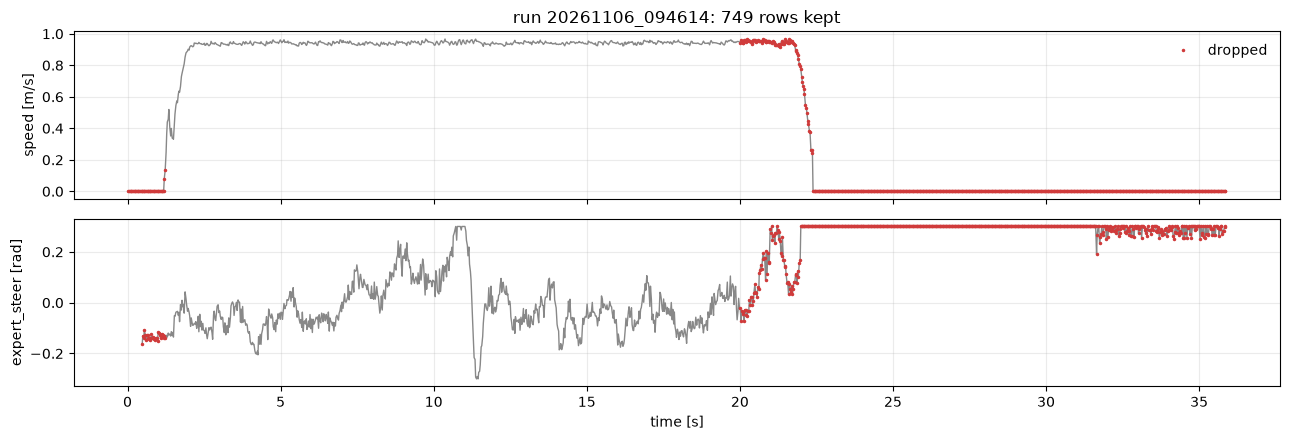

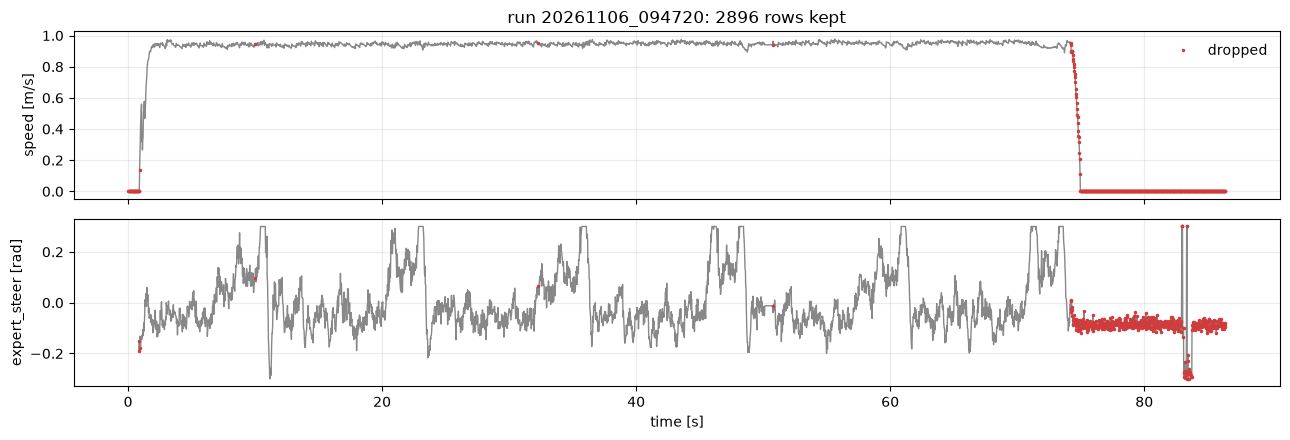

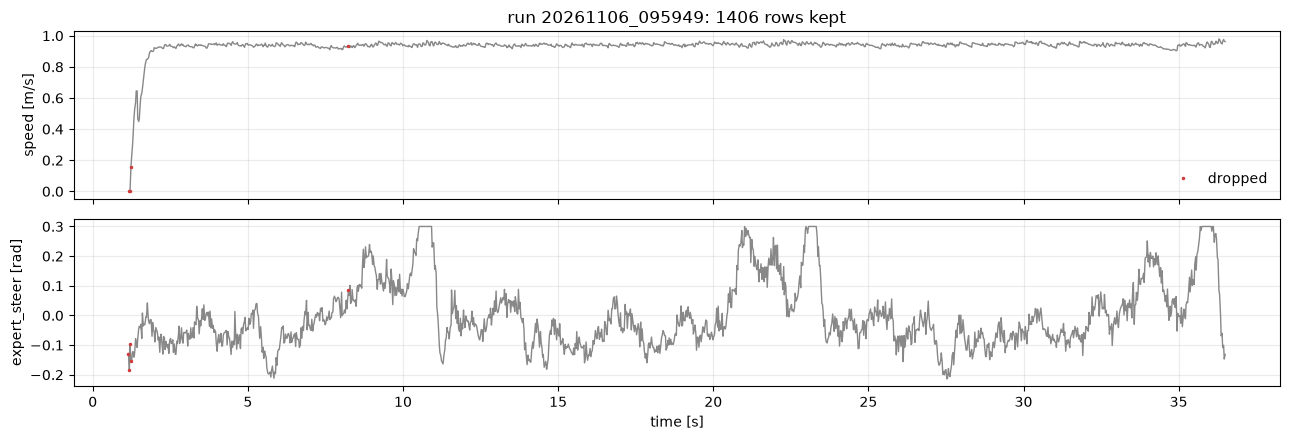

In [62]:
def plot_kept(run_id, cut=None):
    """Plot speed and label over time, with dropped rows marked in red."""
    _, masks, sig = clean_run(run_id, cut=cut, verbose=False)
    t, drop = sig['t'], ~masks['final']
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 4.5), sharex=True)
    for ax, y, name in [(ax1, sig['speed'], 'speed [m/s]'), (ax2, sig['label'], 'expert_steer [rad]')]:
        ax.plot(t, y, color='#888888', lw=1)
        ax.plot(t[drop], y[drop], '.', color='#d03b3b', ms=3, label='dropped')
        ax.set_ylabel(name)
        ax.grid(alpha=0.25)
    ax1.set_title(f'run {run_id}: {masks["final"].sum()} rows kept')
    ax1.legend(frameon=False)
    ax2.set_xlabel('time [s]')
    plt.tight_layout()
    plt.show()


for run_id, cfg in RUNS.items():
    plot_kept(run_id, cut=cfg['cut'])

## Preprocessing: from clean rows to network inputs

The scan reduction and scaling live in **`src/rl_driving/preprocess.py`**, not in this notebook.
The RL sim wrapper and the ROS2 node on the car must use **exactly the same** function, or the network
sees different numbers in the sim and on the car (a classic sim-to-real bug). So the notebook imports it.

`make_observation(ranges, ranges_prev, speed, yaw_rate)` builds one input vector of length `OBS_DIM = 218`:

| part | size | how |
|---|---|---|
| current scan | 108 | invalid beams (NaN, inf, < 0.02, > 30, incl. 65.533) → "far"; clip to 10 m; **min** over groups of 10 beams; ÷ 10 |
| previous scan | 108 | same, for the scan just before |
| speed | 1 | `speed / 3.0` (m/s) |
| yaw rate | 1 | `yaw_rate / 2.0` (rad/s) |

- **Min-pooling, not every 10th beam:** a thin obstacle seen by one beam would disappear if we only kept every 10th beam.
- **Invalid → far before the min:** otherwise a 0.0 or NaN reading would win the min and look like a wall at 0 m.
- **Fixed scales, not dataset mean/std:** the car and the sim must scale identically, whatever data they see.

The label is `steer_to_action(expert_steer) = expert_steer / 0.4189`, so it lies in [-1, 1] (+ = left).

`PREPROC_VERSION` is saved with the dataset. If any constant in the module changes, bump the version and rebuild.

`%autoreload` re-imports the module automatically if you edit it, without restarting the kernel.

In [63]:
%load_ext autoreload
%autoreload 2

from rl_driving.preprocess import (PREPROC_VERSION, N_BEAMS, N_BINS, OBS_DIM, HORIZON,
                                   reduce_scan, make_observation, steer_to_action)

print('preprocessing version:', PREPROC_VERSION)
print(f'{N_BEAMS} beams -> {N_BINS} bins, observation length {OBS_DIM}')

preprocessing version: 1
1081 beams -> 108 bins, observation length 218


### Check: raw scan vs reduced scan
One scan from the half-run. Grey dots are the raw beams (clipped to the 10 m horizon for the plot), the blue line is the 108 bins.
The bins should follow the **lowest** raw points in each group (min-pooling), and "no return" beams (65.533) should show up at the horizon, not at 0.

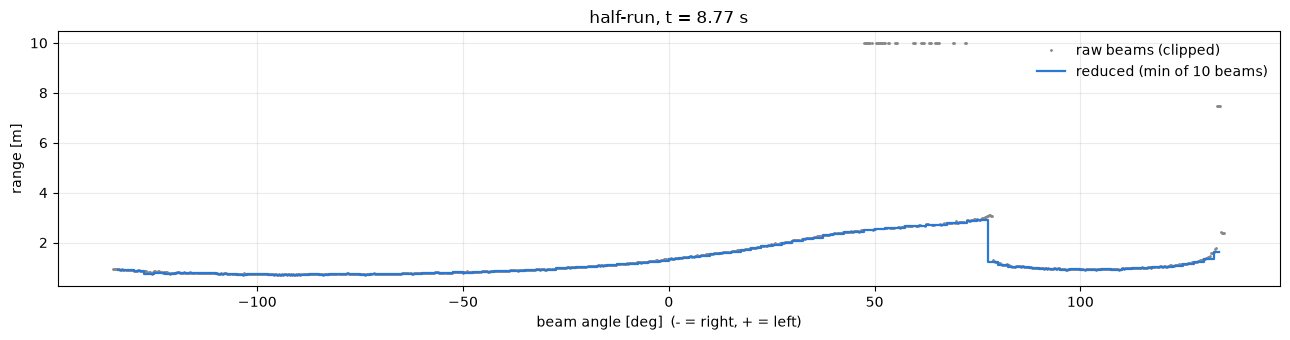

invalid raw beams in this scan: 42


In [64]:
i = 300                                        # a row inside the kept data
raw = half['ranges'][i]
bins = reduce_scan(raw) * HORIZON              # back to metres for plotting

beam_angles = np.linspace(-135, 135, N_BEAMS)
bin_angles = beam_angles[np.arange(0, N_BEAMS - 1, 10)] + 1.25   # centre of each 10-beam bin

fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(beam_angles, np.clip(raw, 0, HORIZON), '.', color='#888888', ms=2, label='raw beams (clipped)')
ax.step(bin_angles, bins, where='mid', color='#2a78d6', lw=1.6, label='reduced (min of 10 beams)')
ax.set_xlabel('beam angle [deg]  (- = right, + = left)'); ax.set_ylabel('range [m]')
ax.set_title(f'half-run, t = {half["t"][i]:.2f} s'); ax.legend(frameon=False); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

print('invalid raw beams in this scan:', ((raw > 30) | (raw < 0.02) | ~np.isfinite(raw)).sum())

### Build X and y for every run
`build_xy` turns one cleaned run into:
- `X`: (rows, 218) observations from `make_observation`
- `y`: (rows,) normalised expert steering in [-1, 1]
- `drift`: (rows,) drift flag, not an input, kept for stats and optional weighting

Then we check that nothing went wrong: no NaN, scan bins inside [0, 1], labels inside [-1, 1].

In [65]:
def build_xy(clean):
    """Turn one cleaned run into (X, y, drift)."""
    X = make_observation(clean['ranges'], clean['ranges_prev'], clean['speed'], clean['yaw_rate'])
    y = steer_to_action(clean['label'])
    return X, y, clean['drift_active'].astype(np.float32)


data = {run_id: build_xy(c) for run_id, c in cleaned.items()}

for run_id, (X, y, drift) in data.items():
    scans = X[:, :2 * N_BINS]
    print(f'{run_id}: X {X.shape}  y {y.shape}  NaN: {np.isnan(X).sum() + np.isnan(y).sum()}  '
          f'scans in [{scans.min():.2f}, {scans.max():.2f}]  '
          f'speed {X[:, -2].mean():.2f}  |yaw| max {np.abs(X[:, -1]).max():.2f}  '
          f'y in [{y.min():.2f}, {y.max():.2f}]')

20261106_094614: X (749, 218)  y (749,)  NaN: 0  scans in [0.04, 1.00]  speed 0.31  |yaw| max 0.76  y in [-0.72, 0.72]
20261106_094720: X (2896, 218)  y (2896,)  NaN: 0  scans in [0.02, 1.00]  speed 0.31  |yaw| max 0.72  y in [-0.72, 0.72]
20261106_095949: X (1406, 218)  y (1406,)  NaN: 0  scans in [0.04, 1.00]  speed 0.31  |yaw| max 0.73  y in [-0.51, 0.72]


### Train / val split, by whole run
Neighbouring scans are almost identical, so a random row split would put near-copies of training rows into
validation and make the val loss look too good. We split by **whole run** instead.

- **val:** half-run (094614)
- **train:** 1-run (094720)
- **fail-run (095949):** not used until we know why it's labelled "fail". It was also recorded with
  `drift_fraction = 0.3` (the others used 0.1), so ~28% of its rows are drift. Set `USE_FAIL_RUN = True`
  once it checks out; it would add ~1400 rows to train.

In [66]:
USE_FAIL_RUN = False

SPLITS = {
    'train': ['20261106_094720'] + (['20261106_095949'] if USE_FAIL_RUN else []),
    'val':   ['20261106_094614'],
}

def stack(run_ids):
    """Concatenate (X, y, drift) of several runs. Safe, because each sample already holds its own previous scan."""
    X = np.concatenate([data[r][0] for r in run_ids])
    y = np.concatenate([data[r][1] for r in run_ids])
    drift = np.concatenate([data[r][2] for r in run_ids])
    return X, y, drift

X_train, y_train, drift_train = stack(SPLITS['train'])
X_val, y_val, drift_val = stack(SPLITS['val'])

for name, X, y, drift in [('train', X_train, y_train, drift_train), ('val', X_val, y_val, drift_val)]:
    print(f'{name:5s}: {len(y):5d} samples, drift {drift.mean():5.1%}, '
          f'y mean {y.mean():+.3f}, y std {y.std():.3f}')

train:  2896 samples, drift 10.9%, y mean +0.012, y std 0.269
val  :   749 samples, drift 15.5%, y mean -0.043, y std 0.239


### Check: label distribution
Train and val should look roughly alike. The wall follower clips at ±0.3 rad, which is ±0.72 after normalising,
so expect spikes at the edges in tight corners. A strong lean to one side is normal: the track turns mostly one way.

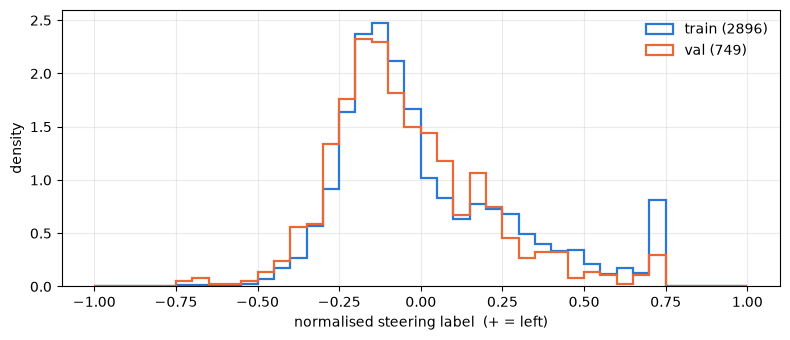

In [67]:
fig, ax = plt.subplots(figsize=(8, 3.5))
edges = np.linspace(-1, 1, 41)
ax.hist(y_train, bins=edges, density=True, histtype='step', lw=1.6, color='#2a78d6', label=f'train ({len(y_train)})')
ax.hist(y_val, bins=edges, density=True, histtype='step', lw=1.6, color='#eb6834', label=f'val ({len(y_val)})')
ax.set_xlabel('normalised steering label  (+ = left)'); ax.set_ylabel('density')
ax.legend(frameon=False); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

### Save
Saves the splits to `../processed/bc_v<PREPROC_VERSION>.npz` (the folder is gitignored), so a training notebook
or script can load them without re-running the cleaning. The file also stores the preprocessing version
and which runs went into each split.

Load later with:
```python
z = np.load('../processed/bc_v1.npz')
X_train, y_train = z['X_train'], z['y_train']
```

In [68]:
os.makedirs('../processed', exist_ok=True)
out_path = f'../processed/bc_v{PREPROC_VERSION}.npz'
np.savez_compressed(
    out_path,
    X_train=X_train, y_train=y_train, drift_train=drift_train,
    X_val=X_val, y_val=y_val, drift_val=drift_val,
    preproc_version=PREPROC_VERSION,
    train_runs=np.array(SPLITS['train']), val_runs=np.array(SPLITS['val']),
)
print('saved', out_path, f'({os.path.getsize(out_path) / 1e6:.1f} MB)')

saved ../processed/bc_v1.npz (0.9 MB)


### Ready for training
In memory (and in `processed/bc_v1.npz`):

| | shape | content |
|---|---|---|
| `X_train`, `X_val` | (N, 218) | 108 + 108 scan bins in [0, 1], speed / 3, yaw rate / 2 |
| `y_train`, `y_val` | (N,) | `expert_steer / 0.4189`, in [-1, 1] |
| `drift_train`, `drift_val` | (N,) | 1 during drift, for stats or sample weighting |

Still open:
1. Check the fail-run and decide on `USE_FAIL_RUN`.
2. All of this is wall_follow data, for building the pipeline. The real BC set will come from cv-nav recordings,
   which only need a new entry in `RUNS`.

In [69]:
# Summary of the datasets ready for training and evaluation.
# Loads the saved file (not the in-memory arrays), so this also checks that the save worked.
ds = np.load(f'../processed/bc_v{PREPROC_VERSION}.npz')
print(f'file: ../processed/bc_v{PREPROC_VERSION}.npz   preprocessing version: {int(ds["preproc_version"])}')
print()

parts = [('current scan', slice(0, N_BINS)), ('previous scan', slice(N_BINS, 2 * N_BINS)),
         ('speed', slice(2 * N_BINS, 2 * N_BINS + 1)), ('yaw rate', slice(2 * N_BINS + 1, OBS_DIM))]

for split in ['train', 'val']:
    X, y, drift = ds[f'X_{split}'], ds[f'y_{split}'], ds[f'drift_{split}']
    runs = ', '.join(ds[f'{split}_runs'])
    print(f'=== {split.upper()}  (runs: {runs})')
    print(f'  X: {X.shape} {X.dtype}    y: {y.shape} {y.dtype}    samples: {len(y)}')
    print(f'  drift rows: {int(drift.sum())} ({drift.mean():.1%})    NaN in X or y: {int(np.isnan(X).sum() + np.isnan(y).sum())}')
    for name, sl in parts:
        v = X[:, sl]
        print(f'  {name:14s} cols {sl.start:3d}-{sl.stop - 1:3d}   min {v.min():+.3f}  mean {v.mean():+.3f}  max {v.max():+.3f}')
    print(f'  {"label y":14s}               min {y.min():+.3f}  mean {y.mean():+.3f}  max {y.max():+.3f}')
    print()

n_train, n_val = len(ds['y_train']), len(ds['y_val'])
print(f'total: {n_train + n_val} samples  ({n_train} train / {n_val} val = {n_val / (n_train + n_val):.0%} val)')

file: ../processed/bc_v1.npz   preprocessing version: 1

=== TRAIN  (runs: 20261106_094720)
  X: (2896, 218) float32    y: (2896,) float32    samples: 2896
  drift rows: 316 (10.9%)    NaN in X or y: 0
  current scan   cols   0-107   min +0.015  mean +0.145  max +1.000
  previous scan  cols 108-215   min +0.015  mean +0.145  max +1.000
  speed          cols 216-216   min +0.077  mean +0.314  max +0.326
  yaw rate       cols 217-217   min -0.441  mean +0.128  max +0.724
  label y                      min -0.716  mean +0.012  max +0.716

=== VAL  (runs: 20261106_094614)
  X: (749, 218) float32    y: (749,) float32    samples: 749
  drift rows: 116 (15.5%)    NaN in X or y: 0
  current scan   cols   0-107   min +0.042  mean +0.139  max +1.000
  previous scan  cols 108-215   min +0.042  mean +0.139  max +1.000
  speed          cols 216-216   min +0.082  mean +0.309  max +0.322
  yaw rate       cols 217-217   min -0.436  mean +0.086  max +0.757
  label y                      min -0.716  mea